# 01 · How to Trade: all models are wrong, some are useful

**Original lecture:** [Quant Guild #22, *How to Trade*](https://github.com/romanmichaelpaolucci/Quant-Guild-Library/tree/main/2025%20Video%20Lectures/22.%20How%20to%20Trade) by Roman Paolucci. This notebook is my own re-implementation and extension of the ideas, written from scratch.

**The question.** When is a trader making money from an edge, and when is the P&L only noise? We build a series of betting games of increasing realism, then test the same logic on real S&P 500 and EUR/USD data.

| Part | Idea | New compared with the original |
|---|---|---|
| 1 | Fair coin: ensemble vs time averages | $\pm\sqrt{n}$ envelope: how far luck alone can carry you |
| 2 | The win probability drifts over time | Reproducible random generator, P&L distributions |
| 3 | A quant estimates the probability from recent history | **Finds and fixes a look-ahead bug** in the original; window-size sweep |
| 4 | Two quants with different models | Heatmap of who wins as a function of both models |
| 5 | Real markets (free data) | Rolling hit-rate signal on SPY & EUR/USD, with a Monte Carlo luck test |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from qgs import load_prices, set_style

set_style()
SEED = 42  # one seed for the whole notebook so every figure is reproducible

## Part 1 · Two naive traders, a fair coin

Heads wins \$1, tails loses \$1, $p = 0.5$. Wealth after $n$ flips is a simple random walk $W_n = \sum_{i=1}^n X_i$ with

$$\mathbb{E}[W_n] = 0, \qquad \operatorname{sd}(W_n) = \sqrt{n}.$$

The **ensemble average** (many players at one point in time) converges to 0, but each *individual* path wanders off by roughly $\sqrt{n}$. After 1,000 flips, a typical player is up or down by about \$32 **with zero skill**. Keep that number in mind whenever someone shows you a P&L curve.

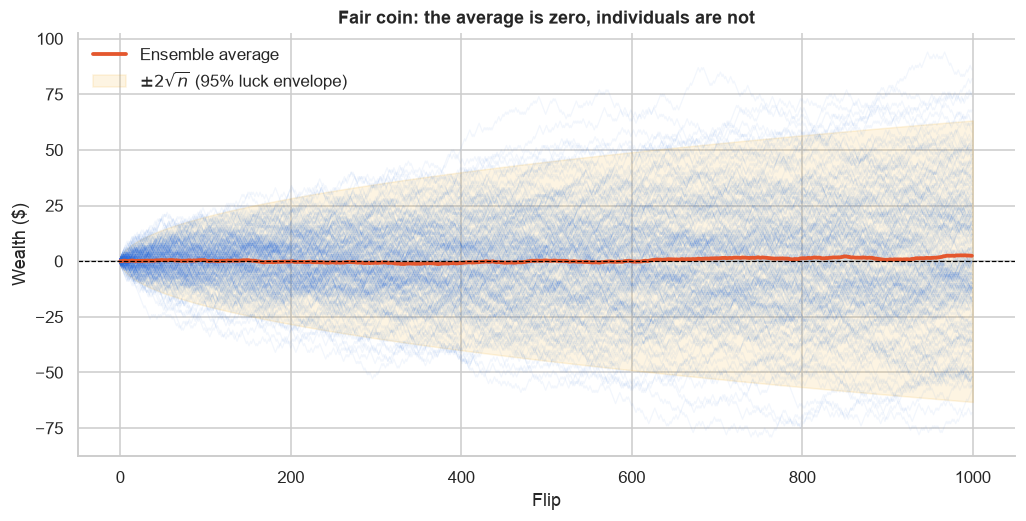

Final wealth: mean +2.5, sd 31.1 (theory: sd = sqrt(1000) = 31.6)
Best 'trader': +86   Worst: -68


In [2]:
rng = np.random.default_rng(SEED)
n_flips, n_players = 1_000, 200

outcomes = rng.choice([-1, 1], size=(n_players, n_flips))
wealth = outcomes.cumsum(axis=1)
t = np.arange(1, n_flips + 1)

fig, ax = plt.subplots()
ax.plot(wealth.T, color="C0", alpha=0.06, lw=0.8)
ax.plot(wealth.mean(axis=0), color="C1", lw=2.5, label="Ensemble average")
ax.fill_between(t, -2 * np.sqrt(t), 2 * np.sqrt(t), color="C3", alpha=0.12, label=r"$\pm 2\sqrt{n}$ (95% luck envelope)")
ax.axhline(0, color="k", lw=0.8, ls="--")
ax.set(title="Fair coin: the average is zero, individuals are not", xlabel="Flip", ylabel="Wealth ($)")
ax.legend(loc="upper left")
plt.show()

final = wealth[:, -1]
print(f"Final wealth: mean {final.mean():+.1f}, sd {final.std():.1f} (theory: sd = sqrt(1000) = {np.sqrt(n_flips):.1f})")
print(f"Best 'trader': {final.max():+d}   Worst: {final.min():+d}")

> **Check yourself:** the best of 200 zero-skill players ends well up. If you only ever heard from that player (survivorship), what would you conclude about their skill?

## Part 2 · A dynamic game: the win probability drifts

Real edges are not constant. Here the win probability $p_t$ follows a bounded random walk whose **drift** is redrawn at random times (the maximum of a Poisson, a Geometric and an Exponential draw, as in the original lecture):

$$p_{t+1} = \operatorname{clip}\left(p_t + \mu_k + \sigma\,\varepsilon_t,\; 0.01,\; 0.99\right), \qquad \mu_k \sim \mathcal N(0, 0.002^2)\ \text{redrawn at each regime change}.$$

A naive trader who always plays, assuming $p = 0.5$, is taking random exposure to an edge that is sometimes positive and sometimes negative.

**Design choice:** the simulator returns the **per-step outcomes** $X_t \in \{-1, +1\}$, not cumulative wealth. Keeping these two apart matters in Part 3.

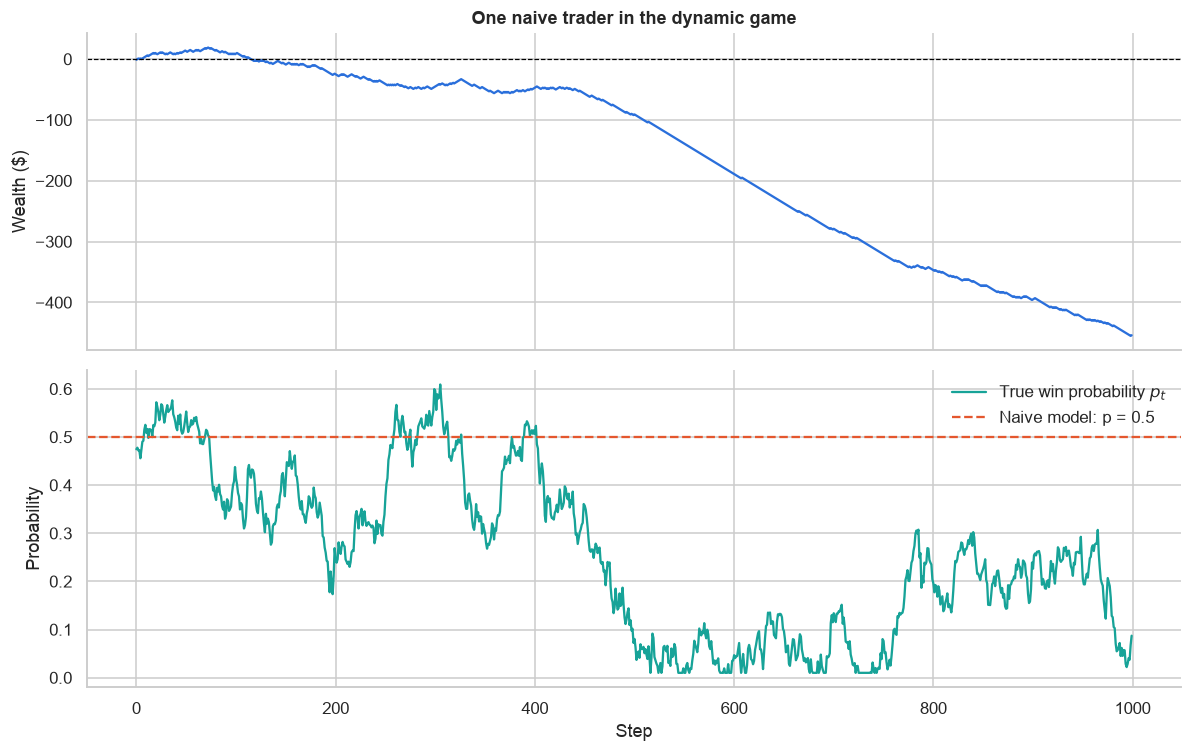

In [3]:
def next_change_time(t, rng):
    return int(max(t + rng.poisson(20), t + rng.geometric(0.05), t + np.floor(rng.exponential(20))))


def simulate_dynamic_game(n_steps, rng, sigma=0.02, drift_sd=0.002):
    # Returns per-step outcomes (+1/-1) and the true win probability path.
    p = np.empty(n_steps)
    current, drift, next_change = 0.5, 0.0, 0
    for t in range(n_steps):
        if t >= next_change:
            drift = rng.normal(0, drift_sd)
            next_change = next_change_time(t, rng)
        current = np.clip(current + drift + rng.normal(0, sigma), 0.01, 0.99)
        p[t] = current
    outcomes = np.where(rng.random(n_steps) < p, 1, -1)
    return outcomes, p


rng = np.random.default_rng(SEED)
n_steps = 1_000
x, p_true = simulate_dynamic_game(n_steps, rng)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax1.plot(x.cumsum(), color="C0")
ax1.axhline(0, color="k", lw=0.8, ls="--")
ax1.set(title="One naive trader in the dynamic game", ylabel="Wealth ($)")
ax2.plot(p_true, color="C2", label="True win probability $p_t$")
ax2.axhline(0.5, color="C1", ls="--", label="Naive model: p = 0.5")
ax2.set(xlabel="Step", ylabel="Probability")
ax2.legend()
plt.tight_layout()
plt.show()

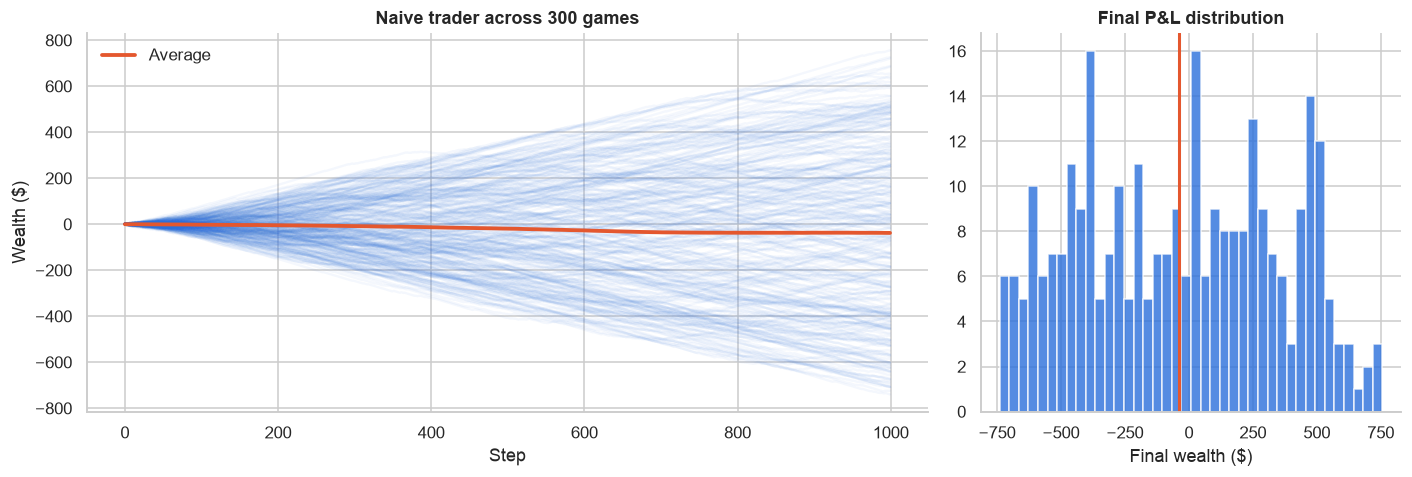

Naive trader: mean final P&L -37.9, sd 390


In [4]:
n_sims = 300
rng = np.random.default_rng(SEED)
games = [simulate_dynamic_game(n_steps, rng) for _ in range(n_sims)]
X = np.array([g[0] for g in games])
P = np.array([g[1] for g in games])

naive_final = X.sum(axis=1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
ax1.plot(X.cumsum(axis=1).T, color="C0", alpha=0.05)
ax1.plot(X.cumsum(axis=1).mean(axis=0), color="C1", lw=2.5, label="Average")
ax1.set(title="Naive trader across 300 games", xlabel="Step", ylabel="Wealth ($)")
ax1.legend()
ax2.hist(naive_final, bins=40, color="C0", alpha=0.8)
ax2.axvline(naive_final.mean(), color="C1", lw=2)
ax2.set(title="Final P&L distribution", xlabel="Final wealth ($)")
plt.tight_layout()
plt.show()
print(f"Naive trader: mean final P&L {naive_final.mean():+.1f}, sd {naive_final.std():.0f}")

The spread of outcomes is **far wider** than in the fair-coin game: a drifting probability creates long streaks. On average, though, the naive trader still has no edge. The mean is small next to the dispersion.

## Part 3 · A quant trader: estimate $p_t$, only play with positive expected value

The quant estimates the current win rate from the last $w$ outcomes and plays only when it looks favourable:

$$\hat p_t = \frac{1}{w}\sum_{i=t-w}^{t-1} \mathbb 1\{X_i = +1\}, \qquad \text{play at } t \iff \hat p_t > 0.5.$$

Note the indices: $\hat p_t$ uses information **up to $t-1$ only**. The decision must be made before the outcome at $t$ is known.

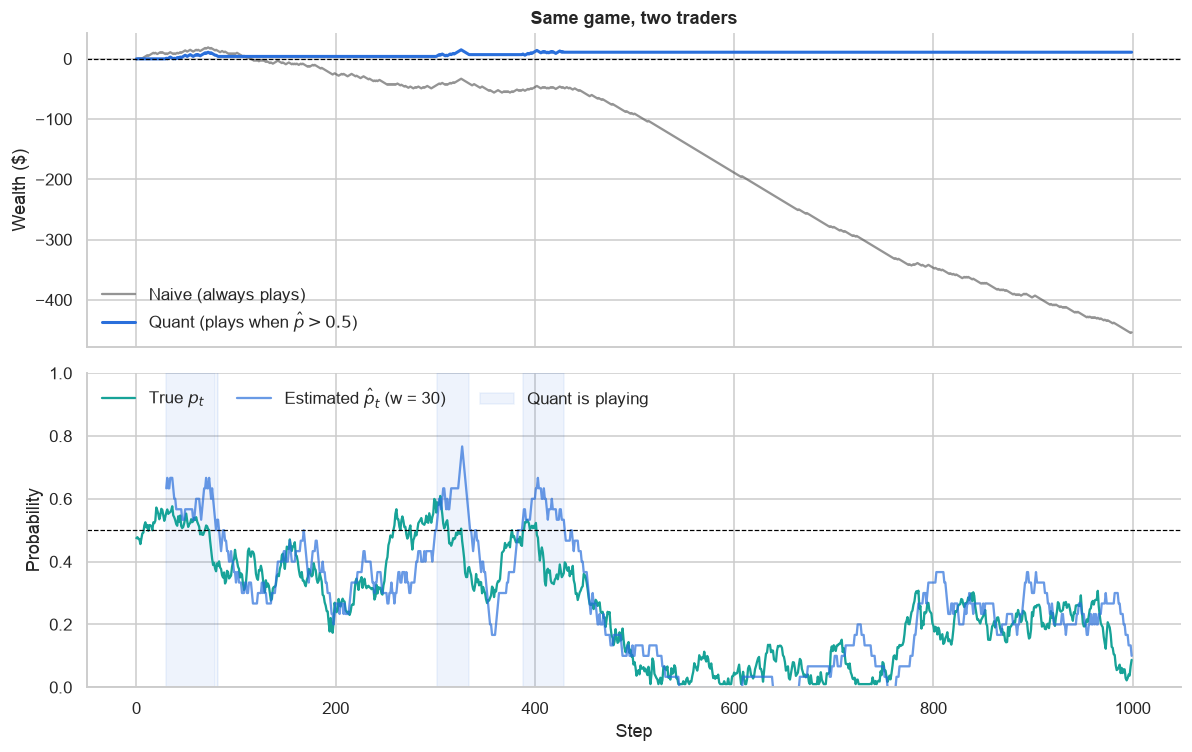

In [5]:
def rolling_hit_rate(outcomes, window):
    # Fraction of wins in the `window` steps *before* each t (NaN until enough history).
    wins = (outcomes > 0).astype(float)
    csum = np.concatenate([[0.0], np.cumsum(wins)])
    est = np.full(len(outcomes), np.nan)
    est[window:] = (csum[window:-1] - csum[: -window - 1]) / window
    return est


def adaptive_pnl(outcomes, window=30, threshold=0.5):
    p_hat = rolling_hit_rate(outcomes, window)
    play = p_hat > threshold  # NaN compares False, so no trades during warm-up
    return np.where(play, outcomes, 0), p_hat, play


pnl, p_hat, play = adaptive_pnl(x, window=30)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax1.plot(x.cumsum(), color="C5", alpha=0.6, label="Naive (always plays)")
ax1.plot(pnl.cumsum(), color="C0", lw=2, label="Quant (plays when $\\hat p > 0.5$)")
ax1.axhline(0, color="k", lw=0.8, ls="--")
ax1.set(title="Same game, two traders", ylabel="Wealth ($)")
ax1.legend()
ax2.plot(p_true, color="C2", label="True $p_t$")
ax2.plot(p_hat, color="C0", alpha=0.7, label="Estimated $\\hat p_t$ (w = 30)")
ax2.fill_between(np.arange(n_steps), 0, 1, where=play, color="C0", alpha=0.08, label="Quant is playing")
ax2.axhline(0.5, color="k", lw=0.8, ls="--")
ax2.set(xlabel="Step", ylabel="Probability", ylim=(0, 1))
ax2.legend(loc="upper left", ncol=3)
plt.tight_layout()
plt.show()

### 🔍 A bug worth learning from: look-ahead through the wrong variable

In the original notebook, the game function returns the **cumulative wealth path**, and the adaptive strategy then treats that array as if it held per-step outcomes:

```python
returns, true_probs = dynamic_probability_game(n_steps)   # actually wealth, not returns
...
if est_prob > 0.5:
    wealth[t] = wealth[t-1] + (1 if returns[t] > 0 else -1)   # tests wealth[t] > 0, not "won at t"
```

So the "signal" becomes *was my wealth above zero recently?*, and the P&L credits +1 whenever the **level** of wealth is above zero. Wealth is highly persistent, so these two line up almost every time. The result is an inflated backtest. Let's measure by how much:

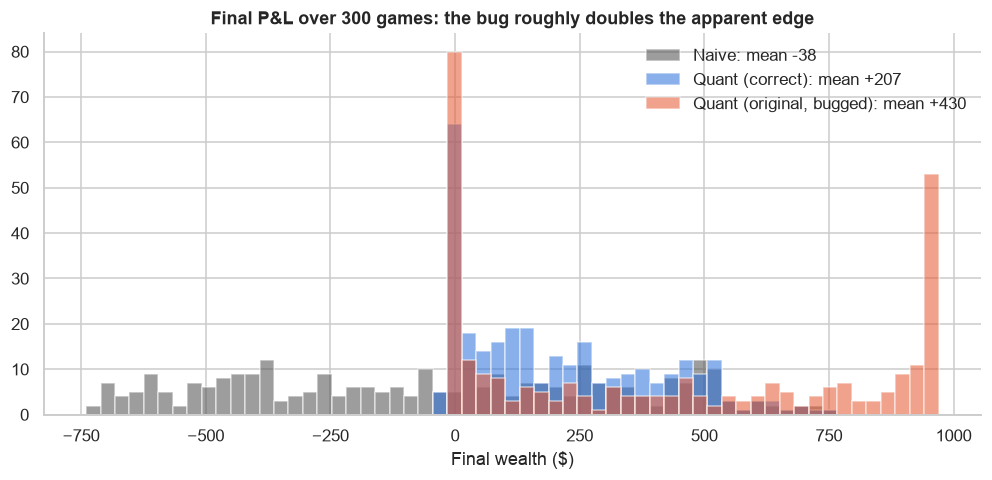

In [6]:
def adaptive_pnl_original_bug(outcomes, window=30):
    # Reproduces the original logic: the cumulative wealth path is used in place of outcomes.
    w = outcomes.cumsum()
    above = (w > 0).astype(float)
    csum = np.concatenate([[0.0], np.cumsum(above)])
    pnl = np.zeros(len(w))
    for t in range(window, len(w)):
        if (csum[t] - csum[t - window]) / window > 0.5:
            pnl[t] = 1 if w[t] > 0 else -1
    return pnl


window = 30
correct = np.array([adaptive_pnl(xi, window)[0].sum() for xi in X])
buggy = np.array([adaptive_pnl_original_bug(xi, window).sum() for xi in X])

fig, ax = plt.subplots(figsize=(11, 4.5))
bins = np.linspace(min(naive_final.min(), correct.min()), buggy.max(), 60)
for data, label, c in [(naive_final, "Naive", "C5"), (correct, "Quant (correct)", "C0"), (buggy, "Quant (original, bugged)", "C1")]:
    ax.hist(data, bins=bins, alpha=0.55, color=c, label=f"{label}: mean {data.mean():+.0f}")
ax.set(title="Final P&L over 300 games: the bug roughly doubles the apparent edge", xlabel="Final wealth ($)")
ax.legend()
plt.show()

**Lesson:** the corrected quant *does* have a real edge, because the true probability is persistent, so the recent past is informative. But the bug inflates it a lot. In a real backtest this kind of error (a level used where a change was meant, or information from time $t$ used to decide at time $t$) is the most common reason a strategy works on paper and fails live. **Always check what each array holds and when it becomes known.**

### Extension: which window is best? (bias vs variance)

A short window reacts quickly but is noisy. A long window is stable but lags. Sweep it:

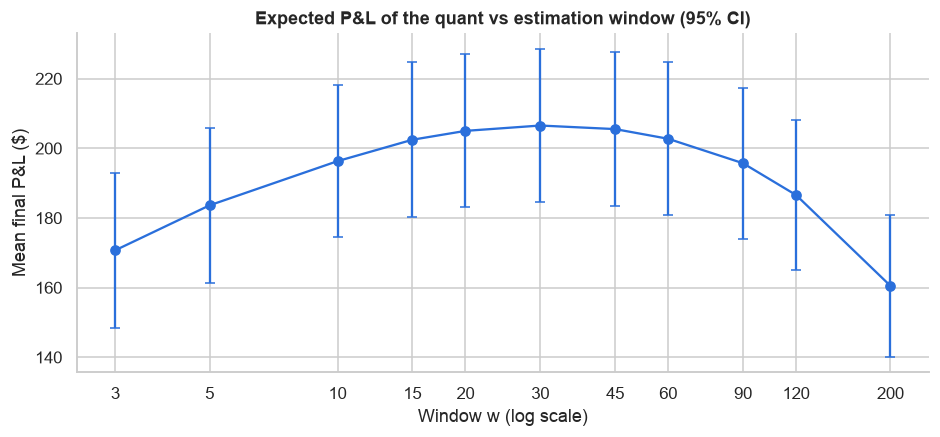

Best window in this game: 30


In [7]:
windows = [3, 5, 10, 15, 20, 30, 45, 60, 90, 120, 200]
mean_pnl = [np.mean([adaptive_pnl(xi, w)[0].sum() for xi in X]) for w in windows]
se_pnl = [np.std([adaptive_pnl(xi, w)[0].sum() for xi in X]) / np.sqrt(n_sims) for w in windows]

fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(windows, mean_pnl, yerr=1.96 * np.array(se_pnl), marker="o", capsize=3)
ax.set_xscale("log")
ax.set_xticks(windows, labels=windows)
ax.set(title="Expected P&L of the quant vs estimation window (95% CI)", xlabel="Window w (log scale)", ylabel="Mean final P&L ($)")
plt.show()
print(f"Best window in this game: {windows[int(np.argmax(mean_pnl))]}")

The optimum depends on **how fast the edge moves** ($\sigma$ and the regime-change rate), a parameter you never observe directly in real markets. That is the "all models are wrong" point in practice: the window *is* the model.

## Part 4 · Two quant traders

**Same model → no trade.** If both sides compute the same $\hat p_t$, they agree on the fair price and never find a counterparty: P&L is flat by construction. A trade needs a **disagreement**.

**Different models.** Trader A uses a window $w_A$ and Trader B uses $w_B$. They trade only when they disagree: B takes the bet when $\hat p^B_t > 0.5 > \hat p^A_t$, and A takes it when $\hat p^A_t > 0.5 > \hat p^B_t$. It's a zero-sum game, so A's gain is B's loss. Below is A's expected P&L for every pair of windows:

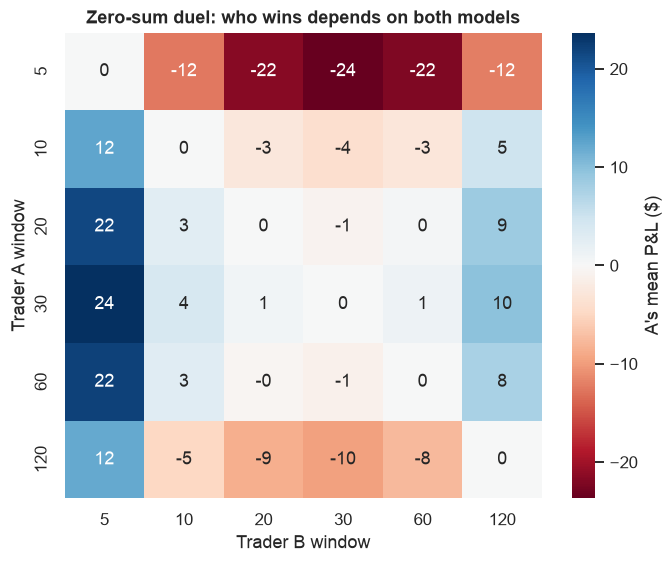

In [8]:
def duel_pnl_A(outcomes, wA, wB):
    pA, pB = rolling_hit_rate(outcomes, wA), rolling_hit_rate(outcomes, wB)
    a_long = (pA > 0.5) & (pB < 0.5)
    b_long = (pB > 0.5) & (pA < 0.5)
    return np.where(a_long, outcomes, 0).sum() - np.where(b_long, outcomes, 0).sum()


grid = [5, 10, 20, 30, 60, 120]
heat = pd.DataFrame(
    [[np.mean([duel_pnl_A(xi, a, b) for xi in X]) for b in grid] for a in grid],
    index=pd.Index(grid, name="Trader A window"),
    columns=pd.Index(grid, name="Trader B window"),
)

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdBu", center=0, ax=ax, cbar_kws={"label": "A's mean P&L ($)"})
ax.set_title("Zero-sum duel: who wins depends on both models")
plt.show()

The heatmap is antisymmetric (A vs B is minus B vs A), with zeros on the diagonal (same model → no trade). The edge belongs to whichever trader's model better matches the **true speed of the game**, not to the trader with the "smarter" model in the abstract. In markets your P&L depends on your model *relative to the other participants'*.

## Part 5 · Does it work on real markets? (free data)

Map the game onto daily returns: a "win" is an up day. The quant goes **long tomorrow** if the hit rate over the last $w$ days is above 50%, and is flat otherwise. We test it on SPY (S&P 500 ETF) and EUR/USD spot, using free Yahoo Finance data.

To avoid the bug from Part 3, the signal is built from returns up to $t-1$ (`shift(1)`), and we charge 1 bp each time the position changes.

In [9]:
prices = load_prices(["SPY", "EURUSD=X"], start="2005-01-01")
rets = np.log(prices).diff().dropna(how="all")
# hit rate among days that moved (Yahoo FX data has some stale zero-return days)
rets.describe().T[["count", "mean", "std"]].assign(hit_rate=(rets > 0).sum() / (rets != 0).where(rets.notna()).sum())

,count,mean,std,hit_rate
SPY,5284.0,0.000420,0.011917,0.553046
EURUSD=X,5637.0,-0.000025,0.006863,0.494923


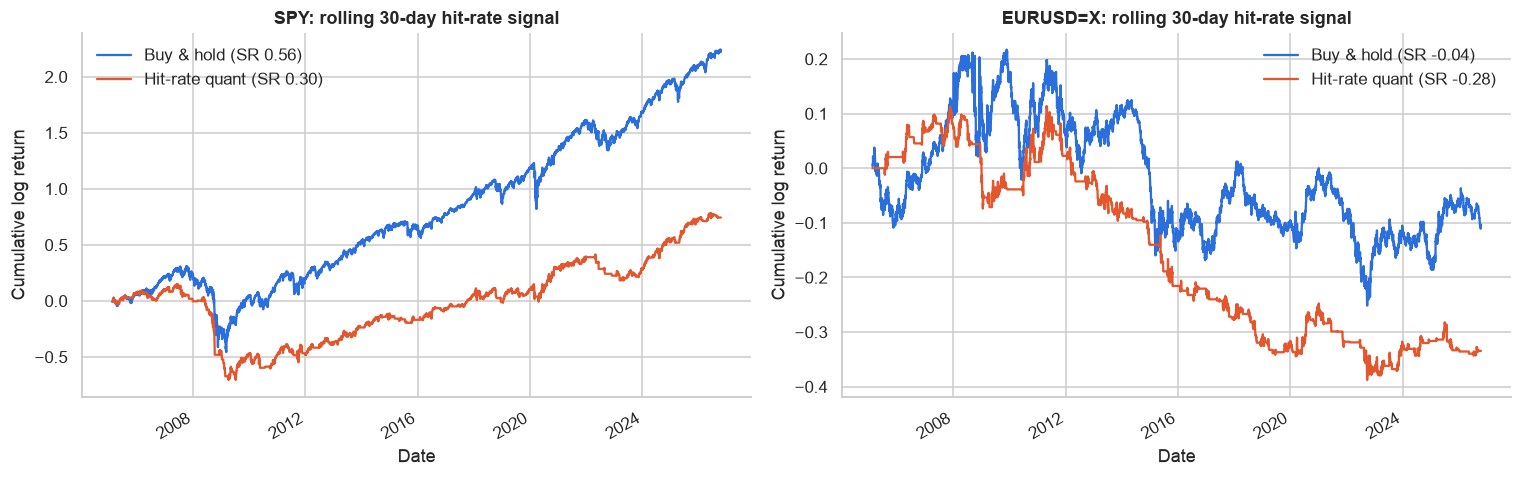

In [10]:
def hit_rate_strategy(r, window=30, cost_bp=1.0):
    r = r.dropna()
    up, moved = (r > 0).astype(float), (r != 0).astype(float)
    # wins / days that moved, using info strictly before day t
    p_hat = (up.rolling(window).sum() / moved.rolling(window).sum()).shift(1)
    pos = (p_hat > 0.5).astype(float)
    costs = pos.diff().abs().fillna(0) * cost_bp / 1e4
    return pd.DataFrame({"strategy": pos * r - costs, "buy_hold": r, "pos": pos, "p_hat": p_hat}).dropna()


def sharpe(x, periods=252):
    return np.sqrt(periods) * x.mean() / x.std()


fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
results = {}
for ax, tic in zip(axes, ["SPY", "EURUSD=X"]):
    res = hit_rate_strategy(rets[tic], window=30)
    results[tic] = res
    res[["buy_hold", "strategy"]].cumsum().plot(ax=ax)
    ax.set(title=f"{tic}: rolling 30-day hit-rate signal", ylabel="Cumulative log return")
    ax.legend([f"Buy & hold (SR {sharpe(res.buy_hold):.2f})", f"Hit-rate quant (SR {sharpe(res.strategy):.2f})"])
plt.tight_layout()
plt.show()

### Is the hit rate actually informative?

If $\hat p_t$ carried information, up-days should be more frequent after the signal fires. Compare $P(\text{up}_t \mid \hat p_t > 0.5)$ with $P(\text{up}_t \mid \hat p_t \le 0.5)$ using a Welch t-test on the 0/1 up-day indicator (equivalent to a two-proportion test at these sample sizes):

In [11]:
rows = []
for tic, res in results.items():
    up = res.buy_hold > 0
    on, off = up[res.pos == 1], up[res.pos == 0]
    _, pval = stats.ttest_ind(on.astype(float), off.astype(float), equal_var=False)
    rows.append({"ticker": tic, "P(up | signal on)": on.mean(), "P(up | signal off)": off.mean(),
                 "days on": len(on), "days off": len(off), "p-value": pval})
pd.DataFrame(rows).set_index("ticker").round(4)

,P(up | signal on),P(up | signal off),days on,days off,p-value
ticker,,,,,
SPY,0.5490,0.5565,3448,1806,0.6053
EURUSD=X,0.4873,0.4972,2212,3395,0.4705


### Luck test: could a random timing rule do as well?

Keep the strategy's exposure (same number of days in the market, same average run length) but place those days at random. We do this by circularly shifting the position series by a random offset, then compare the real Sharpe ratio with that null distribution. This is Part 1's $\pm\sqrt{n}$ envelope, applied to a real backtest.

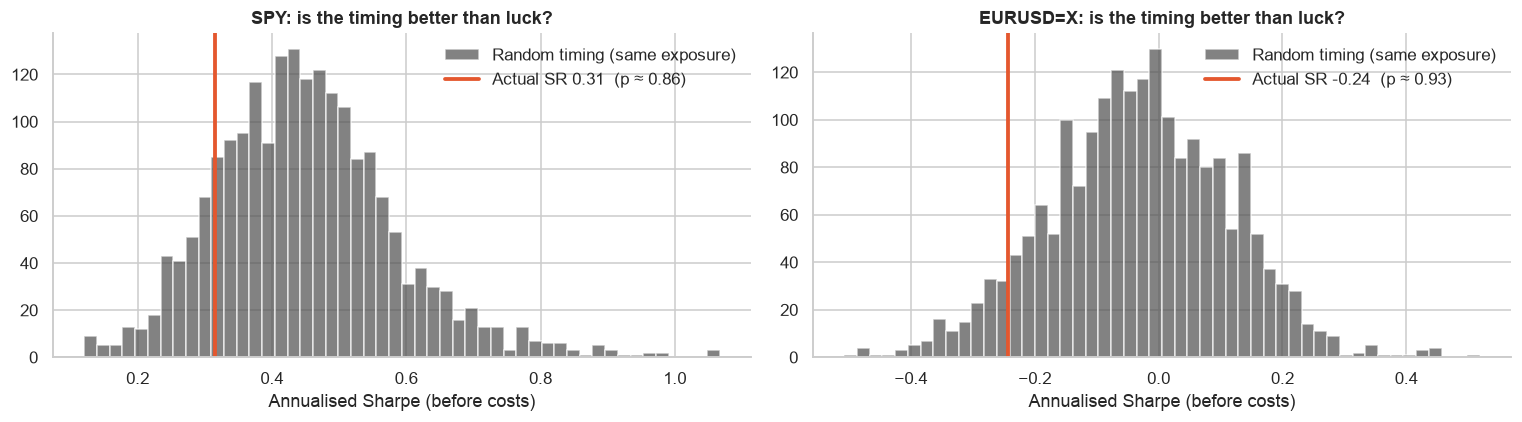

In [12]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (tic, res) in zip(axes, results.items()):
    pos, r = res.pos.values, res.buy_hold.values
    null = np.array([sharpe(pd.Series(np.roll(pos, k) * r)) for k in rng.integers(252, len(r) - 252, 2_000)])
    actual = sharpe(pd.Series(pos * r))
    pct = (null >= actual).mean()
    ax.hist(null, bins=50, color="C5", alpha=0.7, label="Random timing (same exposure)")
    ax.axvline(actual, color="C1", lw=2.5, label=f"Actual SR {actual:.2f}  (p ≈ {pct:.2f})")
    ax.set(title=f"{tic}: is the timing better than luck?", xlabel="Annualised Sharpe (before costs)")
    ax.legend()
plt.tight_layout()
plt.show()

## Takeaways

1. **Luck scales like $\sqrt{n}$.** A zero-skill strategy routinely produces impressive-looking paths. Judge P&L against that envelope, never against zero.
2. **An edge exists only if the world is non-stationary *and* persistent.** In the simulated game the probability drifts slowly, so a rolling estimate earns money. Real daily up/down outcomes in SPY and EUR/USD are close to coin flips, and the same rule is hard to tell apart from random timing.
3. **The model's hyper-parameter is the model.** The best window depends on how fast the edge moves, which you never observe.
4. **Trading is relative.** Identical models never trade. Profit goes to whichever model better matches reality *relative to the counterparty*.
5. **Look-ahead bugs make strategies look great.** Mixing up a level (wealth) with a change (outcome) roughly doubled the apparent edge here. Building signals with explicit timing (`shift(1)`) is the cheapest protection there is.

## Your turn (exercises)

- [ ] Change `sigma` in `simulate_dynamic_game` (0.005, 0.05) and re-run the window sweep. How does the optimal window move? Explain why.
- [ ] Replace the hard threshold `p_hat > 0.5` with a position size proportional to `2 * p_hat - 1` (a preview of Kelly sizing, lecture #36).
- [ ] Run Part 5 on another asset: `^VIX`, `GLD`, `USDJPY=X`, or an FX pair from your own research.
- [ ] Use an exponentially weighted hit rate instead of a rolling window (`.ewm(halflife=...)`). Does it beat the best fixed window?